# LOGISTIC REGRESSION - TANPA PENALTI

### Deskripsi Teori & Varian:
* **Algoritma**: Logistic Regression
* **Varian**: Tanpa Regularisasi (Penalty = None)
* **Konsep**: Model dilatih murni mencari bobot yang meminimalkan error tanpa ada hukuman (regularisasi) sama sekali. Varian ini diuji sebagai pembanding ekstrem untuk membuktikan apakah regularisasi (L1/L2) benar-benar memberikan dampak positif atau justru sebaliknya.

In [1]:
import time
import tracemalloc
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

def clean_text(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1
df_valid['label'] = 0

df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'], test_size=0.2, random_state=42, stratify=df_all['label']
)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Preprocessing Selesai!")

Preprocessing Selesai!


In [2]:
tracemalloc.start()
waktu_mulai = time.time()

# Model Logistic Regression Tanpa Penalti
model = LogisticRegression(penalty=None, solver='lbfgs', max_iter=2000, random_state=42)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: LOGISTIC REGRESSION - TANPA PENALTI")
print("=============================================")
print(f"1. Algoritma        : Logistic Regression")
print(f"2. Metrik Jarak     : Tanpa Regularisasi")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: LOGISTIC REGRESSION - TANPA PENALTI
1. Algoritma        : Logistic Regression
2. Metrik Jarak     : Tanpa Regularisasi
3. Akurasi          : 0.9000
4. Precision (Macro): 0.9006
5. Recall (Macro)   : 0.9000
6. F1-Score (Macro) : 0.9000
7. F1-Score (Weighted): 0.9000
8. Waktu Eksekusi   : 0.0202 detik
9. Penggunaan Memori: 0.60 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.92      0.88      0.90       150
   Hoaks (1)       0.88      0.92      0.90       150

    accuracy                           0.90       300
   macro avg       0.90      0.90      0.90       300
weighted avg       0.90      0.90      0.90       300



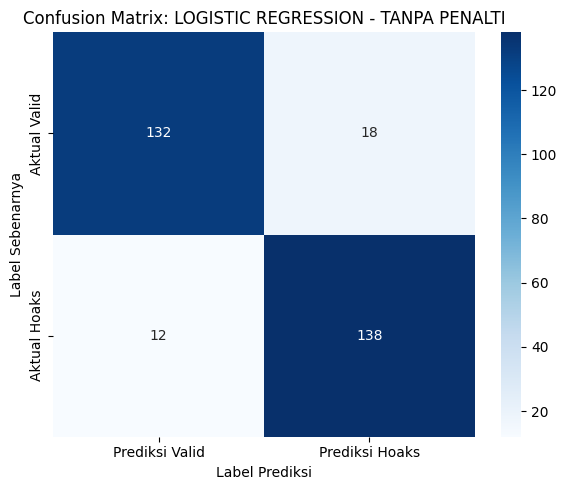

In [3]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: LOGISTIC REGRESSION - TANPA PENALTI')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

### Pembahasan Akademis: Logistic Regression (Tanpa Penalti)

1. **Analisis Performa & Akurasi**:
   * Model tanpa regularisasi (Penalty = None) menghasilkan akurasi sebesar **90.00%** dengan F1-Score 0.9000. 
   * Model ini berhasil menebak 132 berita Valid dan 138 berita Hoaks dengan benar. Hasil ini membuktikan bahwa bahkan tanpa adanya "hukuman" (penalti) pada bobot fitur, model Logistic Regression dasar sudah cukup cerdas untuk memisahkan data teks hoaks dan valid secara linear.

2. **Perbandingan dengan Model Berpenalti**:
   * Meskipun akurasinya tinggi (90.00%), angka ini masih sedikit kalah dibandingkan model L2 (Ridge) yang mencapai **91.00%**.
   * Hal ini membuktikan bahwa penalti L2 (Ridge) memang memberikan nilai tambah. Dengan mengecilkan bobot secara merata, L2 berhasil mencegah model untuk "terlalu percaya diri" pada kata-kata tertentu (noise), sehingga performanya di data uji menjadi lebih optimal dibandingkan model tanpa penalti.

3. **Efisiensi Komputasi**:
   * Waktu eksekusi 0.0202 detik dan memori 0.60 MB. Model ini sangat ringan, membuktikan bahwa kompleksitas tambahan dari regularisasi (L1/L2) tidak memberikan beban komputasi yang berarti, sehingga tetap sangat aman untuk digunakan pada sistem produksi.